# Week 4: Research Methodology for Applied AI

**Concepts:** hypothesis formation, experimental design, confounds, what "rigorous" means at small sample sizes.

**Reading:** *AI Agents That Matter* (Kapoor et al., 2025).

**Lab:** design, on paper, an eval protocol for a specific claim, with explicit success and failure criteria. The protocol itself is in [`notes/week_4/eval_protocol.md`](../notes/week_4/eval_protocol.md). This notebook does the quantitative groundwork for it:

| Section | Question |
|---|---|
| 1. How noisy is accuracy? | How wide is the uncertainty on a score from 30, 150 or 1,000 items? |
| 2. Auditing my own claims | Which Week 2 and Week 3 conclusions survive confidence intervals, paired tests and multiple-comparison correction? |
| 3. The winner's curse | If I pick the "best" prompt on a test set, how much of its advantage is real? |
| 4. Cost and accuracy | Week 3 on a cost-accuracy plot, as Kapoor et al. recommend |
| 5. Power analysis | How many problems does the Week 4 protocol need? |

No model is run here. Every number comes from the per-item results saved in Weeks 2 and 3, so the whole notebook runs in about a minute.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "jupyter" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from stats import (wilson_ci, paired_bootstrap_ci, bootstrap_mean_ci, mcnemar_exact, discordant,
                   sign_flip_test, fisher_exact, holm, power_mcnemar, n_for_power)
from icl import load_sst2

OUT = ROOT / "results" / "week4"; OUT.mkdir(parents=True, exist_ok=True)

# Week 2: rebuild per-item correctness from the saved label log-probs
dev = load_sst2("dev")
TEST = random.Random(0).sample(dev, 150)           # identical to Week 2's test set
GOLD = np.array([e.label for e in TEST])
W2 = [json.loads(l) for l in (ROOT / "results/week2/icl_runs.jsonl").open()]
for r in W2:
    lp, cf = np.array(r["logp"]), np.array(r["cf_logp"])
    r["correct"] = (lp.argmax(1) == GOLD)
    r["correct_cal"] = ((lp - cf).argmax(1) == GOLD)
    assert abs(r["correct"].mean() - r["acc"]) < 1e-6        # matches the accuracy logged in Week 2

# Week 3: per-problem correctness
W3 = [json.loads(l) for l in (ROOT / "results/week3/runs.jsonl").open()]
w3 = {m: np.array([r["correct"] for r in sorted(W3, key=lambda r: r["pid"]) if r["mode"] == m]) for m in ["direct", "cot", "act", "react"]}
TEMPL = np.array([r["template"] for r in sorted(W3, key=lambda r: r["pid"]) if r["mode"] == "react"])
print(f"Week 2: {len(W2)} runs x {len(TEST)} items   Week 3: {len(W3)} runs ({len(w3['react'])} problems x 4 modes)")

Week 2: 140 runs x 150 items   Week 3: 120 runs (30 problems x 4 modes)


## 1. How noisy is an accuracy score?

The Wilson 95% interval for an observed accuracy. At n = 30 (Week 3), a score of 20% is compatible with anything from about 10% to 37%. This is the first thing to compute before believing any result.

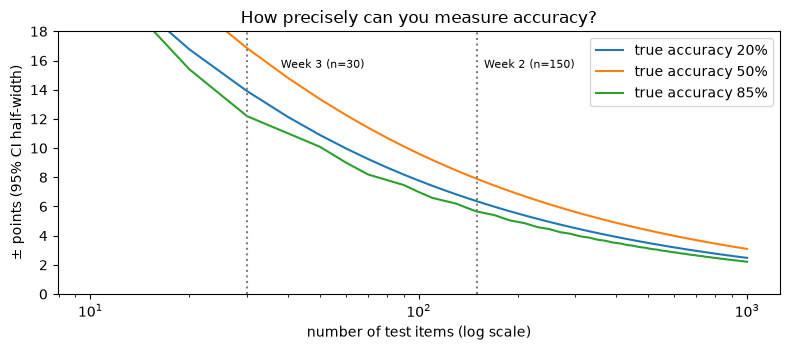

Week 3 direct   0/30 =  0.0%   95% CI  0.0% to 11.4%
Week 3 cot      0/30 =  0.0%   95% CI  0.0% to 11.4%
Week 3 act      7/30 = 23.3%   95% CI 11.8% to 40.9%
Week 3 react    6/30 = 20.0%   95% CI  9.5% to 37.3%


In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ns = np.arange(10, 1001, 10)
for p in [0.2, 0.5, 0.85]:
    ax.plot(ns, [np.subtract(*wilson_ci(round(p * n), n)[::-1]) / 2 * 100 for n in ns], label=f"true accuracy {p:.0%}")
for n, lab in [(30, "Week 3 (n=30)"), (150, "Week 2 (n=150)")]:
    ax.axvline(n, color="grey", ls=":"); ax.text(n + 8, 15.5, lab, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("number of test items (log scale)"); ax.set_ylabel("± points (95% CI half-width)")
ax.set_title("How precisely can you measure accuracy?"); ax.legend(); ax.set_ylim(0, 18)
plt.tight_layout(); plt.savefig(OUT / "ci_width.png", dpi=130); plt.show()

for m, v in w3.items():
    lo, hi = wilson_ci(int(v.sum()), len(v))
    print(f"Week 3 {m:7} {v.sum():2d}/30 = {v.mean():5.1%}   95% CI {lo:5.1%} to {hi:5.1%}")

## 2. Auditing my own claims

Each claim from the Week 2 and 3 notes is tested with the method its design calls for:

- **Paired comparisons** (same items, two conditions): effect = mean per-item difference, 95% CI from a paired bootstrap over items, p-value from a paired sign-flip permutation test (or exact McNemar for single 0/1 runs). Where a condition was run with several demo sets, each item's score is averaged over them first.
- **"No real difference" claims** need *evidence of absence*, so they hold only if the whole 95% CI sits inside ±5 points (an equivalence margin chosen before looking).
- **Threshold claims** ("below chance") hold only if the CI clears the threshold.
- **Holm correction** over all directional p-values, because I'm testing many claims at once.

Verdicts: **holds**, **not established** (the data can't tell), or **overturned** (the data point the other way).

In [3]:
def runs(**kw):
    return [r for r in W2 if all(r.get(k) == v for k, v in kw.items())]

def item_mean(rs, key="correct"):
    return np.mean([r[key] for r in rs], axis=0)      # per-item accuracy averaged over demo sets

claims = []
def directional(cid, text, a, b, binary=False):
    eff, lo, hi = paired_bootstrap_ci(a, b)
    p = mcnemar_exact(*discordant(a, b)) if binary else sign_flip_test(a, b)
    claims.append(dict(id=cid, claim=text, kind="directional", effect=eff, lo=lo, hi=hi, p=p))
def equivalence(cid, text, a, b, margin=0.05):
    eff, lo, hi = paired_bootstrap_ci(a, b)
    claims.append(dict(id=cid, claim=text, kind="equivalence", effect=eff, lo=lo, hi=hi, p=None, margin=margin))
def threshold(cid, text, x, thr, below):
    m, lo, hi = bootstrap_mean_ci(x)
    claims.append(dict(id=cid, claim=text, kind="below" if below else "above", effect=m - thr, lo=lo - thr, hi=hi - thr, p=None, thr=thr))

k0 = runs(exp="count", k=0)[0]["correct"].astype(float)
directional("W2-1", "16 shots beat 0 shots",                    item_mean(runs(exp="count", k=16)), k0)
directional("W2-2", "1 shot is worse than 0 shots",            k0, item_mean(runs(exp="count", k=1)))
equivalence("W2-3", "Random demo labels barely matter (k=8)",  item_mean(runs(exp="labels", variant="gold")), item_mean(runs(exp="labels", variant="random")))
directional("W2-4", "Flipped demo labels hurt (k=8)",          item_mean(runs(exp="labels", variant="gold")), item_mean(runs(exp="labels", variant="flipped")))
threshold("W2-5",   "0.5B model ignores flipped labels (acc > 50%)", item_mean(runs(exp="labels", variant="flipped")), 0.5, below=False)
directional("W2-6", "great/terrible beats positive/negative (4-shot)", item_mean(runs(exp="format", fmt="great/terrible", k=4)), item_mean(runs(exp="format", fmt="review", k=4)))
threshold("W2-7",   "'question' template is below chance (4-shot)", item_mean(runs(exp="format", fmt="question", k=4)), 0.5, below=True)
directional("W2-8", "Calibration rescues the 'question' template", item_mean(runs(exp="format", fmt="question", k=4), "correct_cal"), item_mean(runs(exp="format", fmt="question", k=4)))
directional("W2-9", "Calibration hurts foo/bar labels",          item_mean(runs(exp="format", fmt="foo/bar", k=4)), item_mean(runs(exp="format", fmt="foo/bar", k=4), "correct_cal"))
directional("W2-10", "Instruction does not help a base model (review > review+instr)", item_mean(runs(exp="format", fmt="review", k=4)), item_mean(runs(exp="format", fmt="review+instr", k=4)))

# Recency bias: unit = an ordering (48 orderings over two demo sets), outcome = positive-prediction rate
perm = runs(exp="order")
pos_last = np.array([r["pos_rate"] for r in perm if r["demo_labels"][-1] == 1])
neg_last = np.array([r["pos_rate"] for r in perm if r["demo_labels"][-1] == 0])
obs = pos_last.mean() - neg_last.mean()
rng = np.random.default_rng(0); allp = np.concatenate([pos_last, neg_last])
null = [np.subtract(*[(s := rng.permutation(allp))[:len(pos_last)].mean(), s[len(pos_last):].mean()]) for _ in range(20000)]
p_rec = (np.sum(np.abs(null) >= abs(obs)) + 1) / 20001
boots = [rng.choice(pos_last, len(pos_last)).mean() - rng.choice(neg_last, len(neg_last)).mean() for _ in range(10000)]
claims.append(dict(id="W2-11", claim="Recency: last demo positive raises positive predictions", kind="directional",
                   effect=obs, lo=float(np.quantile(boots, .025)), hi=float(np.quantile(boots, .975)), p=float(p_rec)))

directional("W3-1", "Calculator helps: Act beats CoT",   w3["act"],   w3["cot"],   binary=True)
directional("W3-2", "Calculator helps: ReAct beats CoT", w3["react"], w3["cot"],   binary=True)
equivalence("W3-3", "At 0.5B, ReAct and Act perform the same", w3["react"].astype(float), w3["act"].astype(float))
crates = TEMPL == "crates"; r = w3["react"]
p_f = fisher_exact(int(r[crates].sum()), int((~r[crates]).sum()), int(r[~crates].sum()), int((~r[~crates]).sum()))
eff = r[crates].mean() - r[~crates].mean()
claims.append(dict(id="W3-4", claim="ReAct successes concentrate on the exemplar-shaped template", kind="directional",
                   effect=eff, lo=np.nan, hi=np.nan, p=p_f))

# Holm over directional p-values, then verdicts
dir_idx = [i for i, c in enumerate(claims) if c["kind"] == "directional"]
for i, ph in zip(dir_idx, holm([claims[i]["p"] for i in dir_idx])):
    claims[i]["p_holm"] = ph
for c in claims:
    if c["kind"] == "directional":
        ci_ok = np.isnan(c["lo"]) or c["lo"] > 0
        c["verdict"] = "holds" if (c["p_holm"] < 0.05 and ci_ok) else ("overturned" if c["hi"] < 0 else "not established")
    elif c["kind"] == "equivalence":
        c["verdict"] = "holds" if (c["lo"] > -c["margin"] and c["hi"] < c["margin"]) else \
                       ("overturned" if (c["lo"] > c["margin"] or c["hi"] < -c["margin"]) else "not established")
    elif c["kind"] == "below":
        c["verdict"] = "holds" if c["hi"] < 0 else ("overturned" if c["lo"] > 0 else "not established")
    else:
        c["verdict"] = "holds" if c["lo"] > 0 else ("overturned" if c["hi"] < 0 else "not established")

pct = lambda x: "  n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x*100:+5.1f}"
print(f"{'id':6} {'claim':62} {'effect':>6} {'95% CI':>15} {'p (Holm)':>9}  verdict")
for c in claims:
    ph = f"{c['p_holm']:.4f}" if "p_holm" in c else "    -"
    print(f"{c['id']:6} {c['claim'][:62]:62} {pct(c['effect'])} [{pct(c['lo'])},{pct(c['hi'])}] {ph:>9}  {c['verdict'].upper()}")
json.dump(claims, (OUT / "claim_audit.json").open("w"), indent=1, default=float)
from collections import Counter; print("\n", Counter(c["verdict"] for c in claims))

id     claim                                                          effect          95% CI  p (Holm)  verdict
W2-1   16 shots beat 0 shots                                           +2.7 [ -1.7, +7.3]    0.2707  NOT ESTABLISHED
W2-2   1 shot is worse than 0 shots                                   +13.5 [ +6.5,+20.3]    0.0012  HOLDS
W2-3   Random demo labels barely matter (k=8)                          +1.2 [ -0.3, +2.7]         -  HOLDS
W2-4   Flipped demo labels hurt (k=8)                                  +6.0 [ +2.7, +9.6]    0.0080  HOLDS
W2-5   0.5B model ignores flipped labels (acc > 50%)                  +33.6 [+28.3,+38.5]         -  HOLDS
W2-6   great/terrible beats positive/negative (4-shot)                 +4.0 [ +0.0, +8.0]    0.1243  NOT ESTABLISHED
W2-7   'question' template is below chance (4-shot)                    -1.3 [ -9.1, +6.4]         -  NOT ESTABLISHED
W2-8   Calibration rescues the 'question' template                    +29.1 [+22.4,+36.0]    0.0005  HOLDS
W2

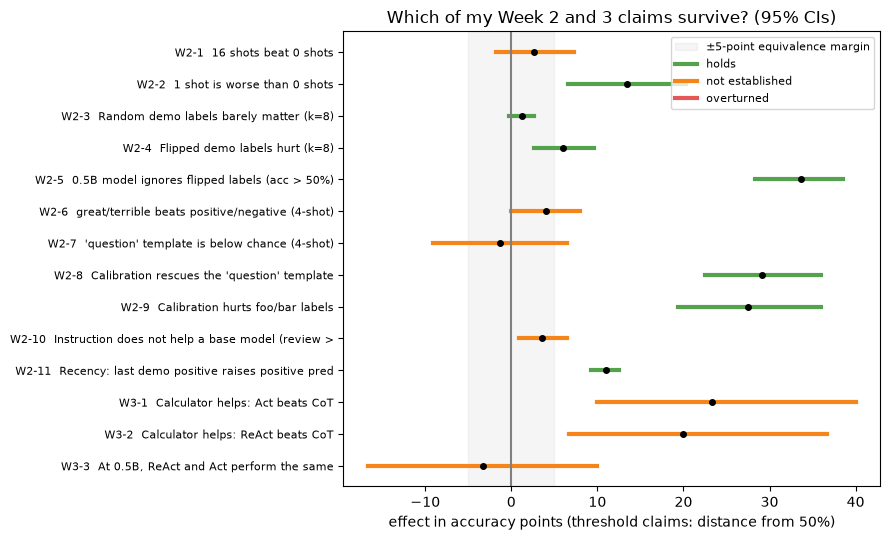

In [4]:
colors = {"holds": "#54A24B", "not established": "#F58518", "overturned": "#E45756"}
cs = [c for c in claims if not np.isnan(c["lo"])][::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, c in enumerate(cs):
    ax.plot([c["lo"] * 100, c["hi"] * 100], [i, i], color=colors[c["verdict"]], lw=3)
    ax.plot(c["effect"] * 100, i, "o", color="black", ms=4)
ax.axvline(0, color="grey"); ax.axvspan(-5, 5, color="grey", alpha=.08, label="±5-point equivalence margin")
ax.set_yticks(range(len(cs))); ax.set_yticklabels([f"{c['id']}  {c['claim'][:48]}" for c in cs], fontsize=8)
ax.set_xlabel("effect in accuracy points (threshold claims: distance from 50%)")
for v, col in colors.items(): ax.plot([], [], color=col, lw=3, label=v)
ax.legend(fontsize=8, loc="upper right"); ax.set_title("Which of my Week 2 and 3 claims survive? (95% CIs)")
plt.tight_layout(); plt.savefig(OUT / "claim_audit.png", dpi=130); plt.show()

## 3. The winner's curse: picking the best prompt on the test set

In Week 2 I reported an 8 to 9 point gap between the best and worst of 24 demo orderings. But I picked "best" and "worst" *after* seeing the test scores, so part of the gap is noise I selected for.

The honest test is to split the 150 items in half 2,000 times, choose the best and worst ordering on one half, and measure them on the other half. This is the holdout logic Kapoor et al. argue most agent benchmarks are missing.

set 100: reported gap (full test set) 8.0 pts | selected on half A 9.2 pts | same orderings on held-out half B 4.8 pts (95% of splits: -2.7 to 9.3); held-out gap > 0 in 93% of splits


set 101: reported gap (full test set) 9.3 pts | selected on half A 10.4 pts | same orderings on held-out half B 6.7 pts (95% of splits: 0.0 to 12.0); held-out gap > 0 in 96% of splits


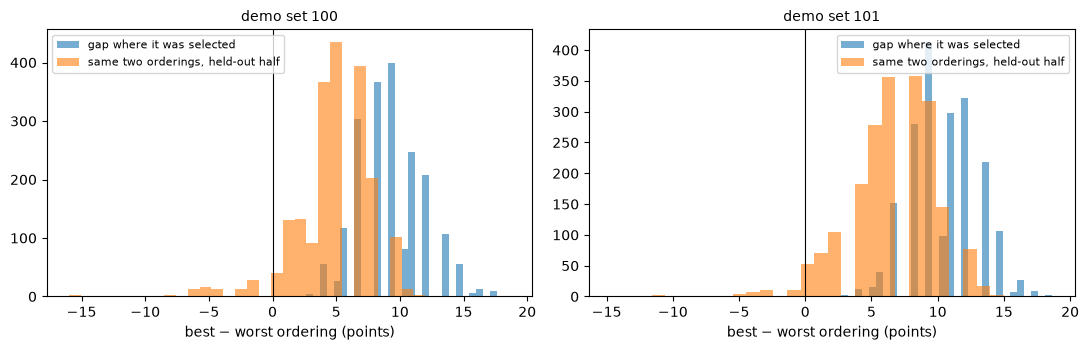

In [5]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for j, s in enumerate([100, 101]):
    M = np.array([r["correct"] for r in runs(exp="order", set=s)], float)   # 24 orderings x 150 items
    insample, heldout = [], []
    for _ in range(2000):
        idx = rng.permutation(150); A, B = idx[:75], idx[75:]
        accA = M[:, A].mean(1); best, worst = accA.argmax(), accA.argmin()
        insample.append(accA[best] - accA[worst]); heldout.append(M[best, B].mean() - M[worst, B].mean())
    insample, heldout = np.array(insample) * 100, np.array(heldout) * 100
    full = (M.mean(1).max() - M.mean(1).min()) * 100
    print(f"set {s}: reported gap (full test set) {full:.1f} pts | selected on half A {insample.mean():.1f} pts | "
          f"same orderings on held-out half B {heldout.mean():.1f} pts (95% of splits: {np.quantile(heldout, .025):.1f} to {np.quantile(heldout, .975):.1f}); "
          f"held-out gap > 0 in {np.mean(heldout > 0):.0%} of splits")
    ax[j].hist(insample, bins=30, alpha=.6, label="gap where it was selected")
    ax[j].hist(heldout, bins=30, alpha=.6, label="same two orderings, held-out half")
    ax[j].axvline(0, color="k", lw=.8); ax[j].set_xlabel("best − worst ordering (points)"); ax[j].set_title(f"demo set {s}", fontsize=10)
    ax[j].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "winners_curse.png", dpi=130); plt.show()

## 4. Cost and accuracy together

Kapoor et al.'s first finding: agent evaluations that report only accuracy reward expensive designs. They recommend plotting accuracy against cost and keeping only designs on the **Pareto frontier** (nothing else is both cheaper and more accurate). Here cost is tokens processed per problem, the quantity that scales API bills and local latency.

direct  tokens/problem    170   accuracy  0.0% (95% CI 0% to 11%)   Pareto frontier
cot     tokens/problem    332   accuracy  0.0% (95% CI 0% to 11%)   
act     tokens/problem   1242   accuracy 23.3% (95% CI 12% to 41%)   Pareto frontier
react   tokens/problem   1569   accuracy 20.0% (95% CI 10% to 37%)   


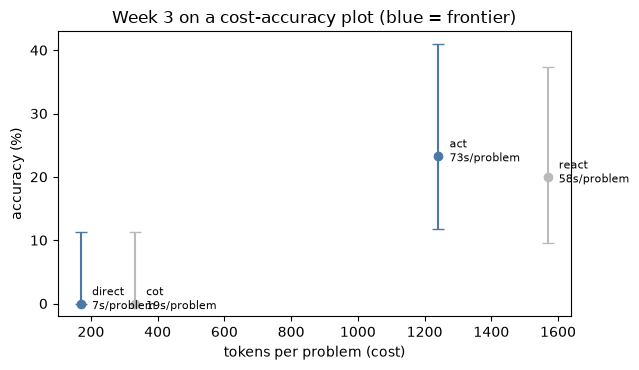

In [6]:
pts = {}
for m in ["direct", "cot", "act", "react"]:
    rs = [r for r in W3 if r["mode"] == m]
    tok = np.mean([r["tokens_in"] + r["tokens_out"] for r in rs]); k = sum(r["correct"] for r in rs)
    pts[m] = (tok, k / len(rs), *wilson_ci(k, len(rs)), np.mean([r["seconds"] for r in rs]))
dominated = lambda m, o: pts[o][0] <= pts[m][0] and pts[o][1] >= pts[m][1] and (pts[o][0] < pts[m][0] or pts[o][1] > pts[m][1])
front = [m for m in pts if not any(dominated(m, o) for o in pts if o != m)]   # nothing else is cheaper-or-equal AND better-or-equal
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for m, (tok, acc, lo, hi, sec) in pts.items():
    ax.errorbar(tok, acc * 100, yerr=[[(acc - lo) * 100], [(hi - acc) * 100]], fmt="o", capsize=4,
                color="#4C78A8" if m in front else "#BBBBBB")
    ax.annotate(f"{m}\n{sec:.0f}s/problem", (tok, acc * 100), textcoords="offset points", xytext=(8, -4), fontsize=8)
    print(f"{m:7} tokens/problem {tok:6.0f}   accuracy {acc:5.1%} (95% CI {lo:.0%} to {hi:.0%})   {'Pareto frontier' if m in front else ''}")
ax.set_xlabel("tokens per problem (cost)"); ax.set_ylabel("accuracy (%)"); ax.set_title("Week 3 on a cost-accuracy plot (blue = frontier)")
plt.tight_layout(); plt.savefig(OUT / "pareto.png", dpi=130); plt.show()

## 5. Power analysis for the Week 4 protocol

The protocol tests whether ReAct beats Act-only by at least 10 points. Both conditions run on the same problems, so the right test is exact McNemar, and its power depends on two numbers:
- **delta**: the true accuracy difference to detect
- **discordance**: the fraction of problems where the two methods disagree (only these carry information)

The Week 3 pilot had a discordance of 5/30 ≈ 17% at 0.5B. Larger models should disagree more often, so the curves cover 20% to 40%.

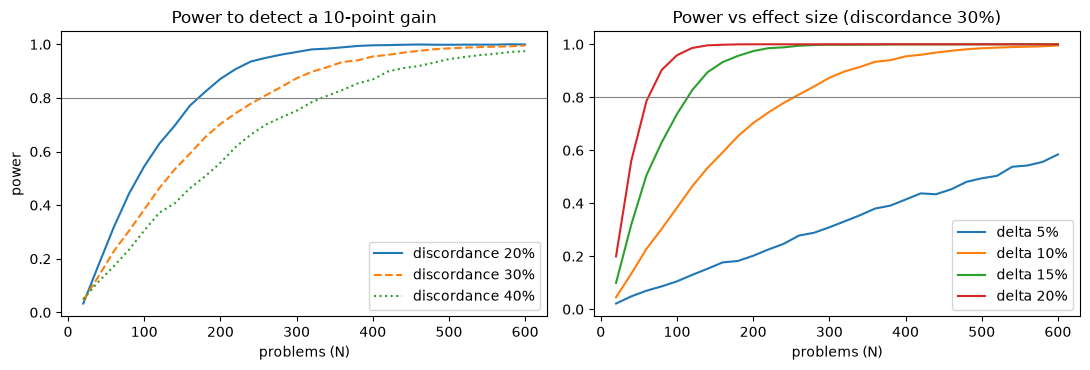

N needed for 80% power (exact McNemar, alpha = 0.05, two-sided):


  discordance 20%: delta 5% -> N=660   delta 10% -> N=180   delta 15% -> N=80   delta 20% -> N=40


  discordance 30%: delta 5% -> N=960   delta 10% -> N=260   delta 15% -> N=120   delta 20% -> N=70


  discordance 40%: delta 5% -> N=1270   delta 10% -> N=330   delta 15% -> N=150   delta 20% -> N=90

Week 3 (N=30, discordance 17%, delta 10%): power = 10%


In [7]:
Ns = list(range(20, 601, 20))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for disc, ls in [(0.2, "-"), (0.3, "--"), (0.4, ":")]:
    ax[0].plot(Ns, [power_mcnemar(n, 0.10, disc) for n in Ns], ls, label=f"discordance {disc:.0%}")
ax[0].axhline(0.8, color="grey", lw=.8); ax[0].set_title("Power to detect a 10-point gain"); ax[0].set_xlabel("problems (N)"); ax[0].set_ylabel("power"); ax[0].legend()
for d in [0.05, 0.10, 0.15, 0.20]:
    ax[1].plot(Ns, [power_mcnemar(n, d, 0.3) for n in Ns], label=f"delta {d:.0%}")
ax[1].axhline(0.8, color="grey", lw=.8); ax[1].set_title("Power vs effect size (discordance 30%)"); ax[1].set_xlabel("problems (N)"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "power.png", dpi=130); plt.show()

print("N needed for 80% power (exact McNemar, alpha = 0.05, two-sided):")
table = {}
for disc in [0.2, 0.3, 0.4]:
    row = {d: n_for_power(d, disc) for d in [0.05, 0.10, 0.15, 0.20] if d <= disc}
    table[disc] = row
    print(f"  discordance {disc:.0%}: " + "   ".join(f"delta {d:.0%} -> N={n}" for d, n in row.items()))
print(f"\nWeek 3 (N=30, discordance 17%, delta 10%): power = {power_mcnemar(30, 0.10, 0.17):.0%}")
json.dump({str(k): {str(d): n for d, n in v.items()} for k, v in table.items()}, (OUT / "power_table.json").open("w"), indent=1)

## Findings

Written up in `notes/week_4/README.md`.